## 10 Expected Values: Claims and Lapses in Dollars

#### Purpose
Notebooks 08a/08b/09 judge the models on **how many** policy-years claim or lapse. Here we turn the probabilities into **dollars**, and check how accurate the probabilities and the dollar figures are:

| Quantity | Formula (each policy-year) | What it answers |
|---|---|---|
| **Expected claims (in USD)** | P(claim) × expected damage ratio × coverage | How much do we expect to pay on this policy-year? |
| **Expected lapsed premium (in USD)** | P(lapse) × premium | How much premium do we expect to lose? |
| **Expected loss ratio** | expected claims ÷ premium | Does the premium cover the expected claims? |
| **A/E in dollars** | actual paid ÷ expected claims | Are the dollar estimates right? (1.00 = exact) |
| **Expected damage ratio** | expected claims ÷ coverage | What share of the insured value do we expect to pay out? |

**Expected damage ratio (the severity part).** We don't know how much a policy will claim before the year starts, so we cannot multiply by the claim itself. Instead we estimate, on the **training years (2014–2020)**, how much a claim pays **as a share of the policy's coverage** (building + contents), by flood zone and coverage size. A $250k policy and a $50k policy then get different expected claim sizes, and the estimate grows with coverage over time. This is the standard actuarial split: **expected loss = claim frequency (our model) × claim severity (the damage ratio)**.

**How accurate are the probabilities?** Next to the log loss of 08b we report:
- **Brier score** = the mean squared error (MSE) of the probability against the 0/1 outcome, and its **skill** (improvement over predicting the training base rate for everyone);
- **RMSE** = √Brier (the same ranking of models, on the scale of a probability);
- **MAD** (mean absolute deviation) on **grouped** totals only: by risk decile and by state, expected vs actual counts and dollars. On single policies MAD rewards predicting 0 for everyone (Step 2.1 shows this), so we don't use it there.

#### Data
The predictions saved by 08a/08b for **both out-of-time splits** (every policy-year, every model), joined to the premium, coverage and claim payments in `features.parquet`:
- **test (OOT1, 2021–2022)**: the years used for tuning;
- **validation (OOT2, 2023 – Aug 2024)**: the holdout.

Nothing is re-predicted, so the probabilities are exactly the ones evaluated in 08a/08b.

#### Steps
0. Setup
1. Expected damage ratio (train) and the data
2. Probability accuracy: Brier, RMSE, log loss
3. Expected claims in dollars and the three ratios
4. Expected lapsed premium
5. Grouped accuracy: RMSE and MAD of expected vs actual, by risk decile and by state
6. Summary and run record

#### Authors
Organized and prepared by Sebastian Carino, Ma. Loisa Celorico, Cyrill Agustin, John Navarro, and Justino Rotairo III.

- **Date Created:** 2026-11-18
- **Date Modified:** 2026-11-18

### Section 0. Setup
Same setup as 08a/08b/09. Before running this notebook, run 08a twice: once with `EVAL_SPLIT = "test"` and once with `EVAL_SPLIT = "valid"`. We read the predictions it saved for both splits.

#### 0.1 Imports, paths and settings

In [1]:
# Find the repo root from any folder, so `src` can be imported
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src.paths import PROCESSED, REPORTS, ensure_dirs
from src.db import connect

pd.options.display.float_format = "{:,.4g}".format
ensure_dirs()

SPLITS = {"test": "OOT1 (test, 2021-2022)", "valid": "OOT2 (validation, 2023 - Aug 2024)"}
OUT = "expected_value"              # prefix of every file saved here
OUT_DIR = REPORTS                   # tables and figures go to reports/
PRED_DIR = PROCESSED / "predictions"

# Expected damage ratio (Step 1.1): cells of flood zone x coverage band, estimated on the training claims
COVERAGE_BANDS = [100_000, 200_000, 300_000]   # upper edges of the bands of building + contents coverage ($)
MIN_CLAIMS = 500                    # a cell with fewer training claims uses its zone's ratio (then the overall one)

con = connect(db_path=None, memory_limit="6GB")
con.execute(f"CREATE OR REPLACE VIEW feats AS SELECT * FROM read_parquet('{PROCESSED / 'features.parquet'}')")

# The models, the primary model of each target and the training base rates, exactly as 08a used them
run_08a = json.loads((REPORTS / "eval_valid_08a_run.json").read_text())
MODELS, PRIMARY = run_08a["models"], run_08a["primary"]
COLS = {kind: {"base rate": "p_base", "segment rule": "p_segment", **{m: f"p_{m}" for m in MODELS[kind]}}
        for kind in MODELS}
NAMES = {"claim_baseline_logreg": "logistic regression", "claim_rf": "random forest", "claim_xgb": "XGBoost",
         "claim_lgbm": "LightGBM", "lapse_baseline_logreg": "logistic regression", "lapse_rf": "random forest",
         "lapse_xgb": "XGBoost", "base rate": "base rate", "segment rule": "segment rule"}
for split in SPLITS:
    for kind in MODELS:
        f = PRED_DIR / f"eval_{split}_{kind}_predictions.parquet"
        assert f.exists(), f"{f.name} is missing: run 08a with EVAL_SPLIT = '{split}'"
for kind in MODELS:
    print(f"{kind}: {[NAMES[m] for m in MODELS[kind]]}; primary {NAMES[PRIMARY[kind]]}")

claim: ['logistic regression', 'LightGBM', 'random forest', 'XGBoost']; primary XGBoost
lapse: ['logistic regression', 'random forest', 'XGBoost']; primary random forest


### Section 1. Expected damage ratio and the data

#### 1.1 Expected damage ratio, estimated on the training years
The damage ratio is the amount paid ÷ the coverage (building + contents). We compute it on the **training claims** (2014–2020) for each **flood zone × coverage band**, as total paid ÷ total coverage of the claims in the cell.

- A claim closed without payment counts as 0, since `CLAIM_IN_TERM` counts it too. So the ratio is the expected payment **given a claim**.
- Negative payments (recoveries) count as 0.
- A cell with fewer than `MIN_CLAIMS` claims uses its zone's ratio, then the overall ratio. The `source` column shows which one is used.

**Check (bottom table):** the **severity A/E** = actual paid ÷ expected paid on the claims of each split. Above 1 means claims got bigger than in training.

In [2]:
# Step 1.1 Expected damage ratio by flood zone x coverage band (training claims)
def band_sql(col):
    """SQL that puts a coverage amount into its band, e.g. '2: $100k-200k'."""
    parts, lo = [], 0
    for i, edge in enumerate(COVERAGE_BANDS, start=1):
        parts.append(f"WHEN {col} <= {edge} THEN '{i}: ${lo // 1000:,}k-{edge // 1000:,}k'")
        lo = edge
    return "CASE " + " ".join(parts) + f" ELSE '{len(COVERAGE_BANDS) + 1}: over ${lo // 1000:,}k' END"

con.execute(f"""
    CREATE OR REPLACE VIEW amounts AS
    SELECT *, {band_sql('coverage')} AS coverage_band
    FROM (SELECT period_id, split, zone_group, in_pop_claim, CLAIM_IN_TERM,
                 GREATEST(COALESCE(building_coverage, 0), 0) + GREATEST(COALESCE(contents_coverage, 0), 0) AS coverage,
                 CASE WHEN premium > 0 THEN premium ELSE 0 END AS premium,
                 GREATEST(COALESCE(claim_paid_total, 0), 0)::DOUBLE AS paid
          FROM feats)""")

train = con.sql("""SELECT zone_group, coverage_band, COUNT(*) AS claims, SUM(paid) AS paid, SUM(coverage) AS coverage
                   FROM amounts WHERE in_pop_claim AND split = 'train' AND CLAIM_IN_TERM = 1 AND coverage > 0
                   GROUP BY ALL ORDER BY ALL""").df()
zone = train.groupby("zone_group")[["claims", "paid", "coverage"]].sum()
overall = train[["claims", "paid", "coverage"]].sum()
DR_OVERALL = overall["paid"] / overall["coverage"]

dr_zone = zone.loc[zone["claims"] >= MIN_CLAIMS].assign(damage_ratio=lambda d: d["paid"] / d["coverage"])
dr_cell = train.loc[train["claims"] >= MIN_CLAIMS].assign(damage_ratio=lambda d: d["paid"] / d["coverage"])
con.register("dr_zone", dr_zone.reset_index()[["zone_group", "damage_ratio"]])
con.register("dr_cell", dr_cell[["zone_group", "coverage_band", "damage_ratio"]])

# The table of every cell, with the ratio it uses
DR = train.merge(dr_cell[["zone_group", "coverage_band", "damage_ratio"]], how="left", on=["zone_group", "coverage_band"])
DR["source"] = np.where(DR["damage_ratio"].notna(), "cell", None)
by_zone = DR["zone_group"].map(dr_zone["damage_ratio"])
DR.loc[DR["source"].isna() & by_zone.notna(), "source"] = "zone"
DR["damage_ratio"] = DR["damage_ratio"].fillna(by_zone)
DR.loc[DR["source"].isna(), "source"] = "overall"
DR["damage_ratio"] = DR["damage_ratio"].fillna(DR_OVERALL)
DR["avg_paid_per_claim"] = DR["paid"] / DR["claims"]
DR.to_csv(OUT_DIR / f"{OUT}_damage_ratio.csv", index=False)
print(f"Overall damage ratio (training claims): {DR_OVERALL:.1%} of coverage")
display(DR.drop(columns=["paid", "coverage"]).style.format(
    {"claims": "{:,}", "damage_ratio": "{:.1%}", "avg_paid_per_claim": "${:,.0f}"}).hide(axis="index"))

# The expected payment of a claim = damage ratio of its cell (or zone, or overall) x its coverage
DR_SQL = f"COALESCE(c.damage_ratio, z.damage_ratio, {DR_OVERALL}) * a.coverage"
severity = con.sql(f"""
    SELECT a.split, COUNT(*) AS claims, SUM(a.paid) / 1e6 AS actual_paid_M, SUM({DR_SQL}) / 1e6 AS expected_paid_M,
           SUM(a.paid) / SUM({DR_SQL}) AS severity_a_to_e, SUM(a.paid) / COUNT(*) AS actual_per_claim,
           SUM({DR_SQL}) / COUNT(*) AS expected_per_claim
    FROM amounts a
    LEFT JOIN dr_cell c ON a.zone_group = c.zone_group AND a.coverage_band = c.coverage_band
    LEFT JOIN dr_zone z ON a.zone_group = z.zone_group
    WHERE a.in_pop_claim AND a.CLAIM_IN_TERM = 1
    GROUP BY 1 ORDER BY CASE a.split WHEN 'train' THEN 1 WHEN 'test' THEN 2 ELSE 3 END""").df()
severity.to_csv(OUT_DIR / f"{OUT}_severity_check.csv", index=False)
display(severity.style.format({"claims": "{:,}", "actual_paid_M": "${:,.0f}M", "expected_paid_M": "${:,.0f}M",
                               "severity_a_to_e": "{:.2f}", "actual_per_claim": "${:,.0f}",
                               "expected_per_claim": "${:,.0f}"}).hide(axis="index"))

Overall damage ratio (training claims): 22.0% of coverage


zone_group,coverage_band,claims,damage_ratio,source,avg_paid_per_claim
A,1: $0k-100k,"40,160",40.1%,cell,"$24,052"
A,2: $100k-200k,"55,453",29.8%,cell,"$44,976"
A,3: $200k-300k,"64,560",21.0%,cell,"$52,854"
A,4: over $300k,"57,131",21.1%,cell,"$81,247"
D,1: $0k-100k,25,22.0%,overall,"$27,123"
D,2: $100k-200k,23,22.0%,overall,"$51,908"
D,3: $200k-300k,49,22.0%,overall,"$87,915"
D,4: over $300k,43,22.0%,overall,"$66,678"
UNKNOWN,1: $0k-100k,51,22.0%,overall,"$26,208"
UNKNOWN,3: $200k-300k,1,22.0%,overall,"$220,332"


split,claims,actual_paid_M,expected_paid_M,severity_a_to_e,actual_per_claim,expected_per_claim
train,"357,822","$19,331M","$19,328M",1.00,"$54,024","$54,016"
test,"83,603","$4,971M","$4,823M",1.03,"$59,454","$57,695"
valid,"89,516","$7,113M","$5,131M",1.39,"$79,457","$57,324"


#### 1.2 The predictions of both splits, with premium, coverage and payments
We join every policy-year scored by 08a to its amounts by `period_id`. Each row has the probability of every model and benchmark, the premium, the coverage, the actual payment and the **expected payment if it claims** (`expected_severity` = damage ratio × coverage).

**Check:** no row is lost in the join.

In [3]:
# Step 1.2 Load the predictions of both splits and join the amounts
def load(kind):
    frames = []
    for split in SPLITS:
        f = PRED_DIR / f"eval_{split}_{kind}_predictions.parquet"
        probs = ", ".join(f"p.{c}::FLOAT AS {c}" for c in COLS[kind].values())
        extra = f", a.coverage, a.coverage_band, a.paid, ({DR_SQL})::FLOAT AS expected_severity" if kind == "claim" else ""
        q = f"""SELECT '{split}' AS split, p.period_year, p.state, a.zone_group, p.y::TINYINT AS y, {probs},
                       a.premium::FLOAT AS premium {extra}
                FROM read_parquet('{f}') p JOIN amounts a USING (period_id)
                LEFT JOIN dr_cell c ON a.zone_group = c.zone_group AND a.coverage_band = c.coverage_band
                LEFT JOIN dr_zone z ON a.zone_group = z.zone_group"""
        df = con.sql(q).df()
        n_file = con.sql(f"SELECT COUNT(*) FROM read_parquet('{f}')").fetchall()[0][0]
        assert len(df) == n_file, f"{kind} {split}: {n_file - len(df):,} rows lost in the join"
        frames.append(df)
    df = pd.concat(frames, ignore_index=True)
    for c in ("split", "state", "zone_group", "coverage_band"):
        if c in df:
            df[c] = df[c].astype("category")
    return df

t0 = time.time()
DATA = {kind: load(kind) for kind in MODELS}
claim = DATA["claim"]
claim["paid"] = claim["paid"].astype("float32")
DATA["lapse"]["lapsed_premium"] = DATA["lapse"]["y"] * DATA["lapse"]["premium"]
for kind, df in DATA.items():
    print(f"{kind}: {len(df):,} policy-years ({df.groupby('split', observed=True).size().to_dict()}), "
          f"{df.memory_usage(deep=True).sum() / 1e9:.1f} GB")
print(f"loaded in {time.time() - t0:.0f}s")

claim: 13,000,507 policy-years ({'test': 7275717, 'valid': 5724790}), 0.7 GB
lapse: 12,726,911 policy-years ({'test': 7105637, 'valid': 5621274}), 0.5 GB
loaded in 12s


### Section 2. Probability accuracy

#### 2.1 Brier score, RMSE and log loss of every model
For each policy-year, the error is the probability minus the outcome (1 if it claimed or lapsed, 0 if not).

| Metric | Formula | Better when | Notes |
|---|---|---|---|
| **Brier (MSE)** | mean of (p − y)² | lower | standard accuracy score for probabilities |
| **Brier skill** | 1 − Brier ÷ Brier of the base rate | higher | > 0 = better than the training base rate |
| **RMSE** | √Brier | lower | same ranking as Brier |
| **Log loss** | mean of −[y log p + (1 − y) log(1 − p)] | lower | punishes confident mistakes most |
| MAD (single policies) | mean of \|p − y\| | — | shown only to explain why we don't use it |

The row **"predict 0 for everyone"** has the **best MAD**, even though it is useless: most outcomes are 0, and MAD does not check whether the probability is honest. Brier and log loss rank it last. So we use MAD only on grouped totals (Section 5).

**Check:** the validation Brier scores should match 08b.

In [4]:
# Step 2.1 Brier, RMSE, log loss (and single-policy MAD) by split
def scores(y, p):
    y, p = y.astype("float64"), np.asarray(p, dtype="float64")
    q = np.clip(p, 1e-6, 1 - 1e-6)
    brier = np.mean((p - y) ** 2)
    return {"brier": brier, "rmse": np.sqrt(brier), "log_loss": -np.mean(y * np.log(q) + (1 - y) * np.log(1 - q)),
            "mad_single": np.mean(np.abs(p - y)), "predicted_rate": p.mean(), "actual_rate": y.mean()}

rows = []
for kind, df in DATA.items():
    for split, g in df.groupby("split", observed=True):
        y = g["y"].to_numpy()
        for name, col in [*COLS[kind].items(), ("predict 0 for everyone", None)]:
            p = np.zeros(len(g)) if col is None else g[col].to_numpy()
            rows.append({"target": kind, "split": split, "model": NAMES.get(name, name), **scores(y, p)})
ACC = pd.DataFrame(rows)
base = ACC[ACC["model"] == "base rate"].set_index(["target", "split"])
key = ACC.set_index(["target", "split"]).index
ACC["brier_skill"] = 1 - ACC["brier"].to_numpy() / base.loc[key, "brier"].to_numpy()
ACC["log_loss_skill"] = 1 - ACC["log_loss"].to_numpy() / base.loc[key, "log_loss"].to_numpy()
ACC["a_to_e"] = ACC["actual_rate"] / ACC["predicted_rate"].replace(0, np.nan)
ACC = ACC[["target", "split", "model", "brier", "brier_skill", "rmse", "log_loss", "log_loss_skill",
           "mad_single", "predicted_rate", "actual_rate", "a_to_e"]]
ACC.to_csv(OUT_DIR / f"{OUT}_probability_accuracy.csv", index=False)

# Check against 08b
for kind in MODELS:
    ref = pd.read_csv(REPORTS / f"eval_valid_{kind}_probability.csv")
    ref = ref[ref["scope"].str.startswith("OOT2")].assign(model=lambda d: d["model"].map(
        lambda m: NAMES.get({"segment rate": "segment rule"}.get(m, m), m))).set_index("model")["brier"]
    mine = ACC.query("target == @kind and split == 'valid'").set_index("model")["brier"]
    common = mine.index.intersection(ref.index)
    print(f"{kind}: largest difference from 08b's validation Brier = {(mine[common] - ref[common]).abs().max():.2e}")

fmt = {"brier": "{:.5f}", "brier_skill": "{:+.1%}", "rmse": "{:.4f}", "log_loss": "{:.4f}", "log_loss_skill": "{:+.1%}",
       "mad_single": "{:.4f}", "predicted_rate": "{:.2%}", "actual_rate": "{:.2%}", "a_to_e": "{:.2f}"}
for kind in MODELS:
    for split in SPLITS:
        print(f"\n{kind}, {SPLITS[split]}")
        t = ACC.query("target == @kind and split == @split").drop(columns=["target", "split"])
        display(t.style.format(fmt, na_rep="-").hide(axis="index")
                .highlight_min(subset=["brier", "log_loss"], color="#d9ead3"))

claim: largest difference from 08b's validation Brier = 2.06e-12
lapse: largest difference from 08b's validation Brier = 2.88e-10

claim, OOT1 (test, 2021-2022)


model,brier,brier_skill,rmse,log_loss,log_loss_skill,mad_single,predicted_rate,actual_rate,a_to_e
base rate,0.01136,+0.0%,0.1066,0.0628,+0.0%,0.0242,1.30%,1.15%,0.88
segment rule,0.01133,+0.3%,0.1064,0.0613,+2.5%,0.0242,1.31%,1.15%,0.88
logistic regression,0.01132,+0.3%,0.1064,0.0611,+2.7%,0.0246,1.36%,1.15%,0.85
LightGBM,0.01147,-1.0%,0.1071,0.0642,-2.2%,0.0222,1.18%,1.15%,0.97
random forest,0.01142,-0.5%,0.1069,0.0636,-1.2%,0.0260,1.51%,1.15%,0.76
XGBoost,0.01146,-0.8%,0.1070,0.0635,-1.1%,0.0222,1.18%,1.15%,0.97
predict 0 for everyone,0.01149,-1.1%,0.1072,0.1588,-152.6%,0.0115,0.00%,1.15%,-



claim, OOT2 (validation, 2023 - Aug 2024)


model,brier,brier_skill,rmse,log_loss,log_loss_skill,mad_single,predicted_rate,actual_rate,a_to_e
base rate,0.01540,+0.0%,0.1241,0.0808,+0.0%,0.0282,1.30%,1.56%,1.20
segment rule,0.01532,+0.5%,0.1238,0.0782,+3.2%,0.0285,1.34%,1.56%,1.17
logistic regression,0.01532,+0.5%,0.1238,0.0784,+3.0%,0.0321,1.72%,1.56%,0.91
LightGBM,0.01579,-2.6%,0.1257,0.0799,+1.1%,0.0281,1.33%,1.56%,1.17
random forest,0.01534,+0.4%,0.1238,0.0761,+5.8%,0.0318,1.71%,1.56%,0.92
XGBoost,0.01576,-2.4%,0.1255,0.0823,-1.8%,0.0259,1.09%,1.56%,1.43
predict 0 for everyone,0.01564,-1.5%,0.1250,0.2160,-167.4%,0.0156,0.00%,1.56%,-



lapse, OOT1 (test, 2021-2022)


model,brier,brier_skill,rmse,log_loss,log_loss_skill,mad_single,predicted_rate,actual_rate,a_to_e
base rate,0.10608,+0.0%,0.3257,0.3688,+0.0%,0.2253,13.84%,12.02%,0.87
segment rule,0.10338,+2.5%,0.3215,0.3582,+2.9%,0.2174,13.39%,12.02%,0.90
logistic regression,0.10219,+3.7%,0.3197,0.3513,+4.7%,0.2001,11.86%,12.02%,1.01
random forest,0.10047,+5.3%,0.3170,0.3438,+6.8%,0.2015,12.05%,12.02%,1.00
XGBoost,0.10107,+4.7%,0.3179,0.3465,+6.0%,0.1950,11.20%,12.02%,1.07
predict 0 for everyone,0.12020,-13.3%,0.3467,1.6606,-350.3%,0.1202,0.00%,12.02%,-



lapse, OOT2 (validation, 2023 - Aug 2024)


model,brier,brier_skill,rmse,log_loss,log_loss_skill,mad_single,predicted_rate,actual_rate,a_to_e
base rate,0.09362,+0.0%,0.3060,0.3373,+0.0%,0.2129,13.84%,10.30%,0.74
segment rule,0.09233,+1.4%,0.3039,0.3307,+2.0%,0.2056,13.29%,10.30%,0.77
logistic regression,0.09328,+0.4%,0.3054,0.3315,+1.7%,0.1928,12.30%,10.30%,0.84
random forest,0.09118,+2.6%,0.3020,0.3252,+3.6%,0.1995,13.02%,10.30%,0.79
XGBoost,0.09151,+2.3%,0.3025,0.3270,+3.1%,0.1897,11.85%,10.30%,0.87
predict 0 for everyone,0.10297,-10.0%,0.3209,1.4226,-321.8%,0.1030,0.00%,10.30%,-


#### 2.2 Brier skill by year
A skill that falls from 2021 to 2024 points to drift (08b, Section 3).

In [5]:
# Step 2.2 Brier skill by year (vs the training base rate)
rows = []
for kind, df in DATA.items():
    for year, g in df.groupby("period_year"):
        y = g["y"].to_numpy().astype("float64")
        b0 = np.mean((g["p_base"].to_numpy() - y) ** 2)
        for name, col in COLS[kind].items():
            rows.append({"target": kind, "year": year, "model": NAMES[name],
                         "brier_skill": 1 - np.mean((g[col].to_numpy() - y) ** 2) / b0})
BY_YEAR = pd.DataFrame(rows).pivot_table(index=["target", "model"], columns="year", values="brier_skill")
BY_YEAR.to_csv(OUT_DIR / f"{OUT}_brier_skill_by_year.csv")
display(BY_YEAR.style.format("{:+.1%}").background_gradient(cmap="RdYlGn", vmin=-0.05, vmax=0.05, axis=None))

### Section 3. Expected claims in dollars

#### 3.1 Expected vs actual claims by year, for every model
**Expected claims ($) = P(claim) × expected damage ratio × coverage**, summed over the year.

The dollar A/E has two parts, **dollar A/E ≈ frequency A/E × severity A/E**:
- **frequency A/E** = actual ÷ expected number of claims: is the probability right?
- **severity A/E** = actual ÷ expected paid per claim: is the damage ratio right?

All models use the same damage ratio, so they differ only in frequency.

Note: some 2024 claims may still be open, so the latest actual dollars may grow.

In [6]:
# Step 3.1 Expected vs actual claims (count and $) by split and year
for name, col in COLS["claim"].items():
    claim[f"e_{col}"] = claim[col] * claim["expected_severity"]

def claim_totals(g):
    out = {"policy_years": len(g), "premium_M": g["premium"].sum() / 1e6, "coverage_B": g["coverage"].sum() / 1e9,
           "actual_claims": g["y"].sum(), "actual_paid_M": g["paid"].sum() / 1e6}
    for name, col in COLS["claim"].items():
        out[f"{name}|expected_claims"] = g[col].sum()
        out[f"{name}|expected_paid_M"] = g[f"e_{col}"].sum() / 1e6
    return pd.Series(out)

rows = []
for (split, year), g in claim.groupby(["split", "period_year"], observed=True):
    rows.append(claim_totals(g).rename((split, str(year))))
for split, g in claim.groupby("split", observed=True):
    rows.append(claim_totals(g).rename((split, "all")))
TOT = pd.DataFrame(rows)

long = []
for name in COLS["claim"]:
    e_n, e_d = TOT[f"{name}|expected_claims"], TOT[f"{name}|expected_paid_M"]
    long.append(pd.DataFrame({"model": NAMES[name], "expected_claims": e_n, "actual_claims": TOT["actual_claims"],
                              "frequency_a_to_e": TOT["actual_claims"] / e_n,
                              "expected_paid_M": e_d, "actual_paid_M": TOT["actual_paid_M"],
                              "dollar_a_to_e": TOT["actual_paid_M"] / e_d}))
CLAIM_EV = pd.concat(long).rename_axis(["split", "year"]).reset_index()
CLAIM_EV["severity_a_to_e"] = CLAIM_EV["dollar_a_to_e"] / CLAIM_EV["frequency_a_to_e"]
CLAIM_EV.to_csv(OUT_DIR / f"{OUT}_claims_by_year.csv", index=False)
display(CLAIM_EV.style.format({"expected_claims": "{:,.0f}", "actual_claims": "{:,.0f}", "frequency_a_to_e": "{:.2f}",
                               "expected_paid_M": "${:,.0f}M", "actual_paid_M": "${:,.0f}M", "dollar_a_to_e": "{:.2f}",
                               "severity_a_to_e": "{:.2f}"}).hide(axis="index"))

split,year,model,expected_claims,actual_claims,frequency_a_to_e,expected_paid_M,actual_paid_M,dollar_a_to_e,severity_a_to_e
test,2021,base rate,"48,833","37,422",0.77,"$2,957M","$1,869M",0.63,0.82
test,2022,base rate,"45,848","46,181",1.01,"$2,793M","$3,101M",1.11,1.10
valid,2023,base rate,"44,809","33,302",0.74,"$2,748M","$2,129M",0.77,1.04
valid,2024,base rate,"29,689","56,214",1.89,"$1,825M","$4,984M",2.73,1.44
test,all,base rate,"94,680","83,603",0.88,"$5,750M","$4,971M",0.86,0.98
valid,all,base rate,"74,498","89,516",1.20,"$4,573M","$7,113M",1.56,1.29
test,2021,segment rule,"48,910","37,422",0.77,"$2,918M","$1,869M",0.64,0.84
test,2022,segment rule,"46,429","46,181",0.99,"$2,787M","$3,101M",1.11,1.12
valid,2023,segment rule,"45,878","33,302",0.73,"$2,774M","$2,129M",0.77,1.06
valid,2024,segment rule,"30,636","56,214",1.83,"$1,857M","$4,984M",2.68,1.46


#### 3.2 The three ratios, for every model

| Ratio | Formula | How to read it |
|---|---|---|
| **Expected loss ratio** | expected claims ÷ premium | below 100%: the premium covers the expected claims |
| **Actual loss ratio** | actual paid ÷ premium | what happened |
| **A/E in dollars** | actual paid ÷ expected claims | 1.00 = exact; above 1 = under-estimated |
| **Expected damage ratio** | expected claims ÷ coverage | share of the insured value we expect to pay out |
| **Actual damage ratio** | actual paid ÷ coverage | share that was paid out |

The loss ratio is **claims ÷ premium only**. NFIP expenses, the reserve fund and the HFIAA surcharge are not included, so it is not the program's reported loss ratio.

In [7]:
# Step 3.2 Expected and actual loss ratio, A/E ($) and damage ratio, by split
ALL = CLAIM_EV[CLAIM_EV["year"] == "all"].drop(columns="year").merge(
    TOT.xs("all", level=1)[["premium_M", "coverage_B"]], left_on="split", right_index=True)
RATIOS = ALL.assign(expected_loss_ratio=ALL["expected_paid_M"] / ALL["premium_M"],
                    actual_loss_ratio=ALL["actual_paid_M"] / ALL["premium_M"],
                    expected_damage_ratio=ALL["expected_paid_M"] / (ALL["coverage_B"] * 1e3),
                    actual_damage_ratio=ALL["actual_paid_M"] / (ALL["coverage_B"] * 1e3))
RATIOS = RATIOS[["split", "model", "premium_M", "expected_paid_M", "actual_paid_M", "expected_loss_ratio",
                 "actual_loss_ratio", "dollar_a_to_e", "expected_damage_ratio", "actual_damage_ratio"]]
RATIOS.to_csv(OUT_DIR / f"{OUT}_claim_ratios.csv", index=False)
display(RATIOS.style.format({"premium_M": "${:,.0f}M", "expected_paid_M": "${:,.0f}M", "actual_paid_M": "${:,.0f}M",
                             "expected_loss_ratio": "{:.0%}", "actual_loss_ratio": "{:.0%}", "dollar_a_to_e": "{:.2f}",
                             "expected_damage_ratio": "{:.3%}", "actual_damage_ratio": "{:.3%}"}).hide(axis="index"))

split,model,premium_M,expected_paid_M,actual_paid_M,expected_loss_ratio,actual_loss_ratio,dollar_a_to_e,expected_damage_ratio,actual_damage_ratio
test,base rate,"$5,883M","$5,750M","$4,971M",98%,84%,0.86,0.273%,0.236%
valid,base rate,"$5,271M","$4,573M","$7,113M",87%,135%,1.56,0.273%,0.424%
test,segment rule,"$5,883M","$5,705M","$4,971M",97%,84%,0.87,0.271%,0.236%
valid,segment rule,"$5,271M","$4,630M","$7,113M",88%,135%,1.54,0.276%,0.424%
test,logistic regression,"$5,883M","$5,722M","$4,971M",97%,84%,0.87,0.272%,0.236%
valid,logistic regression,"$5,271M","$5,851M","$7,113M",111%,135%,1.22,0.349%,0.424%
test,LightGBM,"$5,883M","$4,935M","$4,971M",84%,84%,1.01,0.235%,0.236%
valid,LightGBM,"$5,271M","$4,526M","$7,113M",86%,135%,1.57,0.270%,0.424%
test,random forest,"$5,883M","$6,411M","$4,971M",109%,84%,0.78,0.305%,0.236%
valid,random forest,"$5,271M","$5,840M","$7,113M",111%,135%,1.22,0.348%,0.424%


#### 3.3 The ratios by risk decile and by flood zone (primary claim model)
We rank every policy-year by the primary claim model within its split and cut it into 10 equal groups (decile 10 = riskiest). We check two things:
- **Does the loss ratio rise with risk?** If so, premiums do not rise as fast as the risk (the dollar version of 09, Step 5.2).
- **Is the dollar A/E close to 1 in every decile?** A model can be right in total but wrong at the extremes.

By decile of the XGBoost (10 = riskiest)


split,decile,policy_years,claim_rate,predicted_rate,avg_premium,avg_coverage,expected_paid_M,actual_paid_M,expected_loss_ratio,actual_loss_ratio,dollar_a_to_e,expected_damage_ratio,actual_damage_ratio
test,1,"727,571",0.94%,0.07%,$547,"$305,046",$32M,$479M,8%,120%,15.08,0.014%,0.216%
test,2,"727,572",0.80%,0.16%,$594,"$303,020",$72M,$401M,17%,93%,5.57,0.033%,0.182%
test,3,"727,572",0.73%,0.25%,$633,"$301,924",$113M,$359M,25%,78%,3.17,0.052%,0.164%
test,4,"727,571",0.75%,0.35%,$671,"$299,328",$161M,$365M,33%,75%,2.27,0.074%,0.168%
test,5,"727,572",0.70%,0.48%,$713,"$295,971",$216M,$319M,42%,61%,1.48,0.100%,0.148%
test,6,"727,572",0.71%,0.64%,$760,"$292,266",$283M,$281M,51%,51%,0.99,0.133%,0.132%
test,7,"727,571",0.82%,0.84%,$820,"$286,085",$369M,$327M,62%,55%,0.89,0.177%,0.157%
test,8,"727,572",1.03%,1.15%,$913,"$278,442",$494M,$381M,74%,57%,0.77,0.244%,0.188%
test,9,"727,572",1.43%,1.75%,"$1,050","$269,950",$736M,$561M,96%,73%,0.76,0.375%,0.286%
test,10,"727,572",3.59%,6.11%,"$1,382","$260,417","$2,475M","$1,497M",246%,149%,0.60,1.306%,0.790%


By flood zone


split,zone_group,policy_years,claim_rate,predicted_rate,avg_premium,avg_coverage,expected_paid_M,actual_paid_M,expected_loss_ratio,actual_loss_ratio,dollar_a_to_e,expected_damage_ratio,actual_damage_ratio
test,A,"3,596,813",1.80%,1.42%,"$1,046","$262,534","$2,903M","$4,262M",77%,113%,1.47,0.307%,0.451%
test,D,"2,694",0.74%,0.98%,"$1,737","$289,030",$2M,$0M,37%,8%,0.23,0.220%,0.050%
test,UNKNOWN,219,0.00%,2.54%,$501,"$51,025",$0M,$0M,51%,0%,0.00,0.503%,0.000%
test,V,"98,273",2.71%,2.42%,"$2,278","$276,646",$56M,$178M,25%,79%,3.16,0.207%,0.655%
test,X,"3,577,718",0.45%,0.90%,$528,"$316,459","$1,989M",$530M,105%,28%,0.27,0.176%,0.047%
valid,A,"3,033,296",2.45%,1.30%,"$1,126","$269,191","$2,328M","$6,327M",68%,185%,2.72,0.285%,0.775%
valid,D,"2,338",0.60%,0.67%,"$1,441","$301,440",$1M,$0M,30%,13%,0.44,0.142%,0.062%
valid,UNKNOWN,177,3.95%,2.16%,$375,"$47,401",$0M,$0M,58%,366%,6.34,0.457%,2.895%
valid,V,"89,322",3.54%,2.12%,"$1,790","$282,039",$45M,$275M,28%,172%,6.10,0.179%,1.093%
valid,X,"2,599,657",0.47%,0.81%,$651,"$321,433","$1,325M",$510M,78%,30%,0.38,0.159%,0.061%


/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_59107/3113290595.py:29: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for ax, (split, g) in zip(axes, BY_DECILE.groupby("split")):


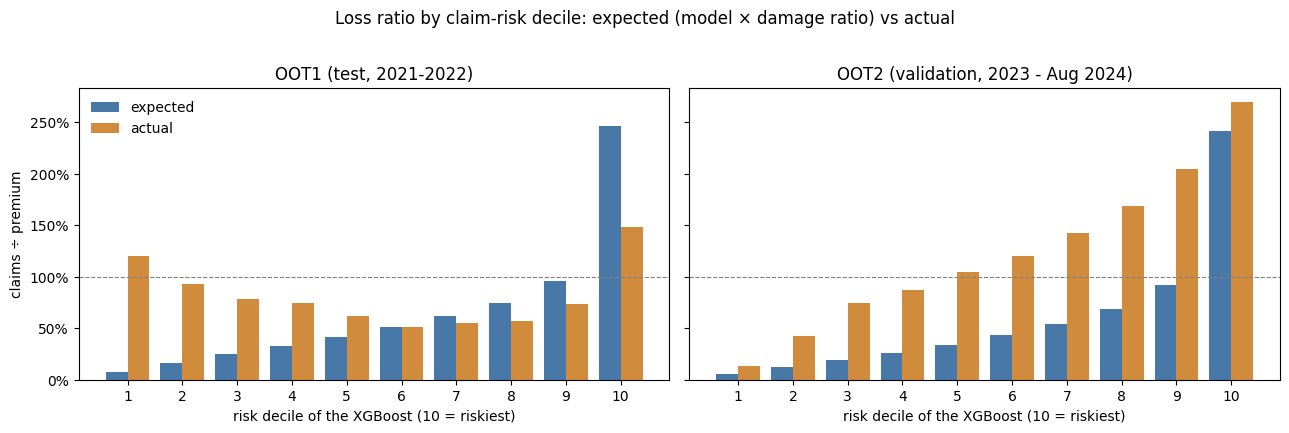

In [8]:
# Step 3.3 Ratios by decile of the primary claim model and by flood zone
col = COLS["claim"][PRIMARY["claim"]]
claim["decile"] = (claim.groupby("split", observed=True)[col].rank(method="first", pct=True) * 10).pipe(np.ceil).astype("int8")

def ratio_table(g):
    e = g[f"e_{col}"].sum()
    return pd.Series({"policy_years": len(g), "claim_rate": g["y"].mean(), "predicted_rate": g[col].mean(),
                      "avg_premium": g["premium"].mean(), "avg_coverage": g["coverage"].mean(),
                      "expected_paid_M": e / 1e6, "actual_paid_M": g["paid"].sum() / 1e6,
                      "expected_loss_ratio": e / g["premium"].sum(), "actual_loss_ratio": g["paid"].sum() / g["premium"].sum(),
                      "dollar_a_to_e": g["paid"].sum() / e, "expected_damage_ratio": e / g["coverage"].sum(),
                      "actual_damage_ratio": g["paid"].sum() / g["coverage"].sum()})

BY_DECILE = claim.groupby(["split", "decile"], observed=True).apply(ratio_table, include_groups=False).reset_index()
BY_ZONE = claim.groupby(["split", "zone_group"], observed=True).apply(ratio_table, include_groups=False).reset_index()
BY_DECILE.to_csv(OUT_DIR / f"{OUT}_claim_ratios_by_decile.csv", index=False)
BY_ZONE.to_csv(OUT_DIR / f"{OUT}_claim_ratios_by_zone.csv", index=False)
rfmt = {"policy_years": "{:,.0f}", "claim_rate": "{:.2%}", "predicted_rate": "{:.2%}", "avg_premium": "${:,.0f}",
        "avg_coverage": "${:,.0f}", "expected_paid_M": "${:,.0f}M", "actual_paid_M": "${:,.0f}M",
        "expected_loss_ratio": "{:.0%}", "actual_loss_ratio": "{:.0%}", "dollar_a_to_e": "{:.2f}",
        "expected_damage_ratio": "{:.3%}", "actual_damage_ratio": "{:.3%}"}
print(f"By decile of the {NAMES[PRIMARY['claim']]} (10 = riskiest)")
display(BY_DECILE.style.format(rfmt).hide(axis="index"))
print("By flood zone")
display(BY_ZONE.style.format(rfmt).hide(axis="index"))

# Chart: expected vs actual loss ratio by decile, one panel per split
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (split, g) in zip(axes, BY_DECILE.groupby("split")):
    x = g["decile"].to_numpy()
    ax.bar(x - 0.2, g["expected_loss_ratio"], width=0.4, color="#4878a8", label="expected")
    ax.bar(x + 0.2, g["actual_loss_ratio"], width=0.4, color="#d08c3c", label="actual")
    ax.axhline(1, color="grey", lw=0.8, ls="--")
    ax.set(title=SPLITS[split], xlabel=f"risk decile of the {NAMES[PRIMARY['claim']]} (10 = riskiest)", xticks=x)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[0].set_ylabel("claims ÷ premium")
axes[0].legend(frameon=False)
fig.suptitle("Loss ratio by claim-risk decile: expected (model × damage ratio) vs actual", y=1.02)
fig.tight_layout()
fig.savefig(OUT_DIR / f"fig_{OUT}_loss_ratio_by_decile.png", dpi=150, bbox_inches="tight")
plt.show()

### Section 4. Expected lapsed premium

#### 4.1 Expected vs actual lapsed premium by year, for every model
**Expected lapsed premium = P(lapse) × premium**, summed over the year. The actual is the premium of the policy-years that lapsed.

We use the models' own probabilities, so the numbers match 08a/08b. 09 (Step 5.1) showed that a yearly recalibration fixes most of the over-prediction in 2023–24.

In [9]:
# Step 4.1 Expected vs actual lapsed premium (count and $) by split and year
lapse = DATA["lapse"]
rows = []
groups = [((s, str(y)), g) for (s, y), g in lapse.groupby(["split", "period_year"], observed=True)]
groups += [((s, "all"), g) for s, g in lapse.groupby("split", observed=True)]
for (split, year), g in groups:
    for name, c in COLS["lapse"].items():
        e = (g[c] * g["premium"]).sum()
        rows.append({"split": split, "year": year, "model": NAMES[name], "policy_years": len(g),
                     "expected_lapses": g[c].sum(), "actual_lapses": g["y"].sum(),
                     "count_a_to_e": g["y"].sum() / g[c].sum(), "premium_M": g["premium"].sum() / 1e6,
                     "expected_lapsed_premium_M": e / 1e6, "actual_lapsed_premium_M": g["lapsed_premium"].sum() / 1e6,
                     "premium_a_to_e": g["lapsed_premium"].sum() / e})
LAPSE_EV = pd.DataFrame(rows)
LAPSE_EV.to_csv(OUT_DIR / f"{OUT}_lapse_by_year.csv", index=False)
display(LAPSE_EV.style.format({"policy_years": "{:,}", "expected_lapses": "{:,.0f}", "actual_lapses": "{:,.0f}",
                               "count_a_to_e": "{:.2f}", "premium_M": "${:,.0f}M", "expected_lapsed_premium_M": "${:,.0f}M",
                               "actual_lapsed_premium_M": "${:,.0f}M", "premium_a_to_e": "{:.2f}"}).hide(axis="index"))

split,year,model,policy_years,expected_lapses,actual_lapses,count_a_to_e,premium_M,expected_lapsed_premium_M,actual_lapsed_premium_M,premium_a_to_e
test,2021,base rate,"3,648,441","504,918","465,877",0.92,"$2,976M",$412M,$384M,0.93
test,2021,segment rule,"3,648,441","478,033","465,877",0.97,"$2,976M",$380M,$384M,1.01
test,2021,logistic regression,"3,648,441","425,582","465,877",1.09,"$2,976M",$375M,$384M,1.02
test,2021,random forest,"3,648,441","420,882","465,877",1.11,"$2,976M",$381M,$384M,1.01
test,2021,XGBoost,"3,648,441","402,793","465,877",1.16,"$2,976M",$354M,$384M,1.08
test,2022,base rate,"3,457,196","478,451","388,207",0.81,"$2,757M",$382M,$303M,0.79
test,2022,segment rule,"3,457,196","473,704","388,207",0.82,"$2,757M",$384M,$303M,0.79
test,2022,logistic regression,"3,457,196","416,892","388,207",0.93,"$2,757M",$362M,$303M,0.84
test,2022,random forest,"3,457,196","435,648","388,207",0.89,"$2,757M",$369M,$303M,0.82
test,2022,XGBoost,"3,457,196","393,105","388,207",0.99,"$2,757M",$338M,$303M,0.90


#### 4.2 Lapsed premium by risk decile (primary lapse model)
Same deciles as Step 3.3, for the primary lapse model. If the expected and actual bars move together, the model ranks **premium at risk** well, not just lapse counts.

split,decile,policy_years,lapse_rate,predicted_rate,avg_premium,expected_lapsed_premium_M,actual_lapsed_premium_M,premium_a_to_e
test,1,"710,563",2.9%,3.6%,$678,$17.8M,$14.1M,0.79
test,2,"710,564",4.9%,5.8%,$759,$31.5M,$25.9M,0.82
test,3,"710,564",6.7%,7.3%,$773,$40.2M,$35.5M,0.88
test,4,"710,563",8.3%,8.7%,$768,$47.3M,$43.5M,0.92
test,5,"710,564",9.9%,10.0%,$755,$53.7M,$50.6M,0.94
test,6,"710,564",11.3%,11.4%,$747,$60.8M,$57.3M,0.94
test,7,"710,563",13.3%,13.1%,$757,$70.4M,$68.3M,0.97
test,8,"710,564",16.2%,15.1%,$780,$83.7M,$84.0M,1.00
test,9,"710,564",19.7%,18.0%,$879,$112.8M,$110.9M,0.98
test,10,"710,564",27.1%,27.5%,"$1,172",$230.9M,$196.4M,0.85


/var/folders/n3/thbcrffd11792rp8v7cn203m0000gn/T/ipykernel_59107/2917406118.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for ax, (split, g) in zip(axes, LAPSE_DEC.groupby("split")):


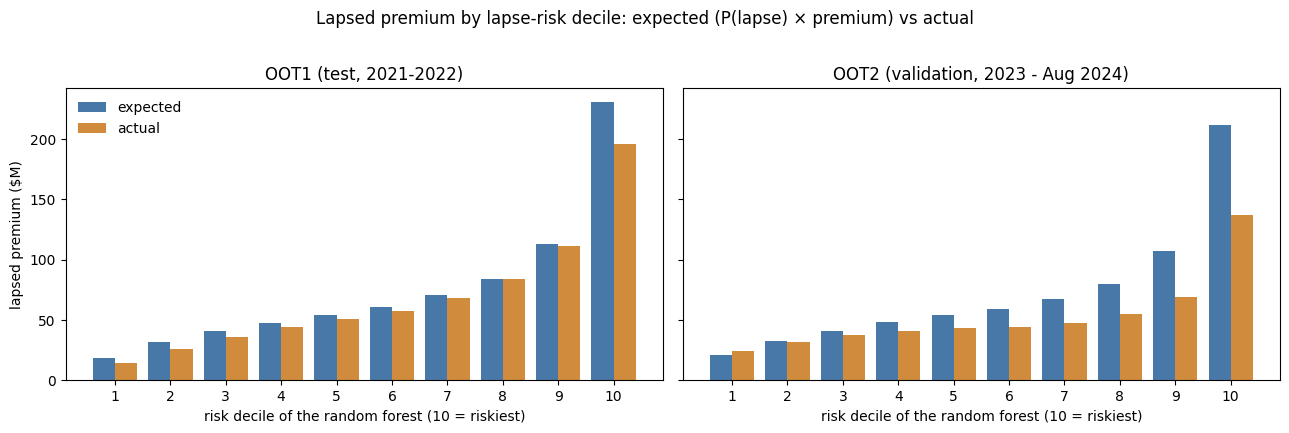

In [10]:
# Step 4.2 Expected vs actual lapsed premium by decile of the primary lapse model
col_l = COLS["lapse"][PRIMARY["lapse"]]
lapse["decile"] = (lapse.groupby("split", observed=True)[col_l].rank(method="first", pct=True) * 10).pipe(np.ceil).astype("int8")
lapse["e_premium"] = lapse[col_l] * lapse["premium"]
LAPSE_DEC = (lapse.groupby(["split", "decile"], observed=True)
             .agg(policy_years=("y", "size"), lapse_rate=("y", "mean"), predicted_rate=(col_l, "mean"),
                  avg_premium=("premium", "mean"), expected_lapsed_premium_M=("e_premium", "sum"),
                  actual_lapsed_premium_M=("lapsed_premium", "sum")).reset_index())
LAPSE_DEC[["expected_lapsed_premium_M", "actual_lapsed_premium_M"]] /= 1e6
LAPSE_DEC["premium_a_to_e"] = LAPSE_DEC["actual_lapsed_premium_M"] / LAPSE_DEC["expected_lapsed_premium_M"]
LAPSE_DEC.to_csv(OUT_DIR / f"{OUT}_lapse_by_decile.csv", index=False)
display(LAPSE_DEC.style.format({"policy_years": "{:,}", "lapse_rate": "{:.1%}", "predicted_rate": "{:.1%}",
                                "avg_premium": "${:,.0f}", "expected_lapsed_premium_M": "${:,.1f}M",
                                "actual_lapsed_premium_M": "${:,.1f}M", "premium_a_to_e": "{:.2f}"}).hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (split, g) in zip(axes, LAPSE_DEC.groupby("split")):
    x = g["decile"].to_numpy()
    ax.bar(x - 0.2, g["expected_lapsed_premium_M"], width=0.4, color="#4878a8", label="expected")
    ax.bar(x + 0.2, g["actual_lapsed_premium_M"], width=0.4, color="#d08c3c", label="actual")
    ax.set(title=SPLITS[split], xlabel=f"risk decile of the {NAMES[PRIMARY['lapse']]} (10 = riskiest)", xticks=x)
axes[0].set_ylabel("lapsed premium ($M)")
axes[0].legend(frameon=False)
fig.suptitle("Lapsed premium by lapse-risk decile: expected (P(lapse) × premium) vs actual", y=1.02)
fig.tight_layout()
fig.savefig(OUT_DIR / f"fig_{OUT}_lapsed_premium_by_decile.png", dpi=150, bbox_inches="tight")
plt.show()

### Section 5. Grouped accuracy: RMSE and MAD of expected vs actual

#### 5.1 By risk decile and by state
Here we compare **expected totals** with **actual totals** over groups of policy-years. MAD makes sense here, because a group's expected total can be compared directly with what happened.
- **RMSE** = √ mean of (expected − actual)²: big misses count most.
- **MAD** = mean of |expected − actual|: the typical miss.
- **MAD %** = MAD ÷ mean actual per group: the typical miss as a share of the actual.

Two groupings:
- **(a) risk decile × year**, using each model's own deciles: is the model right at every risk level? The benchmarks are left out, since their scores barely vary.
- **(b) state × year**: the same groups for every model and benchmark, as a planning or reserving team would use them.

Measures: claim counts, claim dollars, lapse counts and lapsed premium.

In [11]:
# Step 5.1 RMSE and MAD of expected vs actual totals by group
def grouped_errors(df, groups, expected, actual):
    t = df.groupby(groups, observed=True).agg(e=(expected, "sum"), a=(actual, "sum"))
    t = t[t["a"].notna()]
    d = t["e"] - t["a"]
    return {"groups": len(t), "rmse": np.sqrt(np.mean(d ** 2)), "mad": np.mean(np.abs(d)),
            "mad_pct": np.mean(np.abs(d)) / np.mean(t["a"]), "a_to_e": t["a"].sum() / t["e"].sum()}

MEASURES = {"claim": [("claim count", lambda c: c, "y"), ("claim $", lambda c: f"e_{c}", "paid")],
            "lapse": [("lapse count", lambda c: c, "y"), ("lapsed premium $", lambda c: f"e_{c}", "lapsed_premium")]}
for name, c in COLS["lapse"].items():
    lapse[f"e_{c}"] = lapse[c] * lapse["premium"]

rows = []
for kind, df in DATA.items():
    for name, c in COLS[kind].items():
        if name not in ("base rate", "segment rule"):   # (a) the model's own deciles x year
            df["_dec"] = (df.groupby(["split", "period_year"], observed=True)[c].rank(method="first", pct=True) * 10).pipe(np.ceil)
        for split, g in df.groupby("split", observed=True):
            for measure, e_col, a_col in MEASURES[kind]:
                if name not in ("base rate", "segment rule"):
                    rows.append({"target": kind, "split": split, "grouping": "(a) decile x year", "measure": measure,
                                 "model": NAMES[name], **grouped_errors(g, ["period_year", "_dec"], e_col(c), a_col)})
                rows.append({"target": kind, "split": split, "grouping": "(b) state x year", "measure": measure,
                             "model": NAMES[name], **grouped_errors(g, ["period_year", "state"], e_col(c), a_col)})
    df.drop(columns="_dec", inplace=True)
GROUPED = pd.DataFrame(rows)
GROUPED.to_csv(OUT_DIR / f"{OUT}_grouped_accuracy.csv", index=False)

gfmt = {"groups": "{:,}", "rmse": "{:,.0f}", "mad": "{:,.0f}", "mad_pct": "{:.1%}", "a_to_e": "{:.2f}"}
for (kind, measure), t in GROUPED.groupby(["target", "measure"], sort=False):
    print(f"\n{measure} ($ for the dollar measures)")
    t = t.drop(columns=["target", "measure"]).sort_values(["grouping", "split", "mad_pct"])
    display(t.style.format(gfmt).hide(axis="index"))


claim count ($ for the dollar measures)


split,grouping,model,groups,rmse,mad,mad_pct,a_to_e
test,(a) decile x year,logistic regression,20,"1,089",780,18.7%,0.85
test,(a) decile x year,XGBoost,20,"3,485","2,209",52.8%,0.97
test,(a) decile x year,LightGBM,20,"4,226","2,359",56.4%,0.97
test,(a) decile x year,random forest,20,"3,800","2,494",59.7%,0.76
valid,(a) decile x year,logistic regression,20,"2,447","2,030",45.4%,0.91
valid,(a) decile x year,random forest,20,"3,576","2,279",50.9%,0.92
valid,(a) decile x year,XGBoost,20,"3,160","2,303",51.4%,1.43
valid,(a) decile x year,LightGBM,20,"4,143","2,450",54.7%,1.17
test,(b) state x year,LightGBM,110,"2,424",598,78.7%,0.97
test,(b) state x year,XGBoost,110,"2,696",621,81.7%,0.97



claim $ ($ for the dollar measures)


split,grouping,model,groups,rmse,mad,mad_pct,a_to_e
test,(a) decile x year,logistic regression,20,"65,047,240","59,599,688",24.0%,0.87
test,(a) decile x year,XGBoost,20,"207,726,496","149,415,392",60.1%,1.00
test,(a) decile x year,LightGBM,20,"259,725,792","165,002,000",66.4%,1.01
test,(a) decile x year,random forest,20,"241,362,720","169,685,536",68.3%,0.78
valid,(a) decile x year,logistic regression,20,"242,578,240","197,134,800",55.4%,1.22
valid,(a) decile x year,LightGBM,20,"335,214,176","197,997,984",55.7%,1.57
valid,(a) decile x year,XGBoost,20,"294,780,320","206,215,904",58.0%,1.92
valid,(a) decile x year,random forest,20,"409,289,376","229,730,016",64.6%,1.22
test,(b) state x year,LightGBM,110,"199,227,920","44,413,280",98.3%,1.01
test,(b) state x year,XGBoost,110,"216,887,632","46,315,696",102.5%,1.00



lapse count ($ for the dollar measures)


split,grouping,model,groups,rmse,mad,mad_pct,a_to_e
test,(a) decile x year,logistic regression,20,"7,346","5,346",12.5%,1.01
test,(a) decile x year,random forest,20,"7,593","5,729",13.4%,1.00
test,(a) decile x year,XGBoost,20,"9,443","6,972",16.3%,1.07
valid,(a) decile x year,XGBoost,20,"10,615","6,741",23.3%,0.87
valid,(a) decile x year,random forest,20,"10,277","8,094",28.0%,0.79
valid,(a) decile x year,logistic regression,20,"14,893","9,555",33.0%,0.84
test,(b) state x year,XGBoost,110,"3,074",966,12.4%,1.07
test,(b) state x year,random forest,110,"3,223","1,003",12.9%,1.00
test,(b) state x year,logistic regression,110,"3,173","1,015",13.1%,1.01
test,(b) state x year,segment rule,110,"4,085","1,452",18.7%,0.90



lapsed premium $ ($ for the dollar measures)


split,grouping,model,groups,rmse,mad,mad_pct,a_to_e
test,(a) decile x year,random forest,20,"7,967,376","4,748,523",13.8%,0.92
test,(a) decile x year,XGBoost,20,"9,697,596","5,484,653",16.0%,0.99
test,(a) decile x year,logistic regression,20,"12,193,954","6,516,440",19.0%,0.93
valid,(a) decile x year,XGBoost,20,"16,319,033","9,096,059",34.4%,0.79
valid,(a) decile x year,random forest,20,"14,762,713","9,969,479",37.8%,0.73
valid,(a) decile x year,logistic regression,20,"23,195,510","12,527,158",47.4%,0.75
test,(b) state x year,XGBoost,110,"2,020,449","702,252",11.3%,0.99
test,(b) state x year,random forest,110,"2,582,641","913,760",14.6%,0.92
test,(b) state x year,logistic regression,110,"3,005,172","954,350",15.3%,0.93
test,(b) state x year,segment rule,110,"3,524,179","1,264,935",20.3%,0.90


### Section 6. Summary and run record

#### 6.1 Headline table
One row per model and split: Brier skill, dollar A/E and the typical miss by state (MAD %).

In [12]:
# Step 6.1 Headline: accuracy of the probabilities and of the dollar totals
acc = ACC.set_index(["target", "split", "model"])[["brier_skill", "log_loss_skill", "a_to_e"]]
dollars = pd.concat([CLAIM_EV[CLAIM_EV["year"] == "all"].assign(target="claim").rename(columns={"dollar_a_to_e": "dollar_a_to_e"}),
                     LAPSE_EV[LAPSE_EV["year"] == "all"].assign(target="lapse").rename(columns={"premium_a_to_e": "dollar_a_to_e"})])
dollars = dollars.set_index(["target", "split", "model"])[["dollar_a_to_e"]]
state = (GROUPED[(GROUPED["grouping"] == "(b) state x year") & GROUPED["measure"].str.contains(r"\$")]
         .set_index(["target", "split", "model"])[["mad_pct"]].rename(columns={"mad_pct": "state_mad_pct_dollars"}))
HEADLINE = acc.join(dollars, how="inner").join(state).rename(columns={"a_to_e": "count_a_to_e"}).reset_index()
HEADLINE.to_csv(OUT_DIR / f"{OUT}_headline.csv", index=False)
display(HEADLINE.style.format({"brier_skill": "{:+.1%}", "log_loss_skill": "{:+.1%}", "count_a_to_e": "{:.2f}",
                               "dollar_a_to_e": "{:.2f}", "state_mad_pct_dollars": "{:.1%}"}).hide(axis="index"))

target,split,model,brier_skill,log_loss_skill,count_a_to_e,dollar_a_to_e,state_mad_pct_dollars
claim,test,base rate,+0.0%,+0.0%,0.88,0.86,111.6%
claim,test,segment rule,+0.3%,+2.5%,0.88,0.87,110.1%
claim,test,logistic regression,+0.3%,+2.7%,0.85,0.87,108.1%
claim,test,LightGBM,-1.0%,-2.2%,0.97,1.01,98.3%
claim,test,random forest,-0.5%,-1.2%,0.76,0.78,120.4%
claim,test,XGBoost,-0.8%,-1.1%,0.97,1.00,102.5%
claim,valid,base rate,+0.0%,+0.0%,1.20,1.56,99.6%
claim,valid,segment rule,+0.5%,+3.2%,1.17,1.54,99.9%
claim,valid,logistic regression,+0.5%,+3.0%,0.91,1.22,105.0%
claim,valid,LightGBM,-2.6%,+1.1%,1.17,1.57,90.7%


#### 6.2 What we found
*Final run, 2026-11-18. Test = OOT1 (2021–2022); validation = OOT2 (2023 – Aug 2024). Loss ratios are claims ÷ premium only.*

**1. Claims got bigger in 2023–24 (Step 1.1).**
- A training claim pays **22% of coverage** on average. The share falls as coverage grows: in zone A, 40% up to $100k and 21% above $300k; in zone V, 28% to 7%.
- **Severity A/E** is 1.03 on test but **1.39** on validation: the average claim paid **$79,500** against $57,300 expected (Debby, Helene and Milton in 2024). So every dollar estimate on validation starts about 39% low.

**2. Probability accuracy (Steps 2.1–2.2).**
- **Lapse:** the random forest has the best Brier skill (+5.3% test, +2.6% validation), with XGBoost close (+4.7%, +2.3%). Its skill falls from +6.6% (2021) to +2.1% (2024): the drift 08b found after Risk Rating 2.0.
- **Claims:** on validation, only the logistic regression (+0.5%), the segment rule (+0.5%) and the random forest (+0.4%) beat the base rate. **XGBoost (−2.4%) and LightGBM (−2.6%) do worse**: they were trained on every claim plus 10% of the rest and tuned for ranking, so they rank well but their probabilities are off.
- RMSE adds nothing new (it is √Brier).
- **"Predict 0 for everyone" has the best single-policy MAD** (claims, test: 0.0115 against 0.022 or more for every model) but the worst log loss. So MAD is only used on grouped totals.

**3. Expected claims in dollars (Steps 3.1–3.2).**
- **Test:** XGBoost and LightGBM are almost exact (dollar A/E 1.00 and 1.01), partly because the two years offset each other (XGBoost: 0.75 in 2021, 1.27 in 2022). The random forest over-estimates (0.78), and the logistic regression and benchmarks slightly (0.86–0.87).
- **Validation:** every model under-estimates. Best: **logistic regression and random forest (1.22)**. Worst: **XGBoost (1.92 = frequency 1.43 × severity 1.34)**, then LightGBM (1.57) and the base rate (1.56).
- **2023 was over-estimated** (0.62–0.98) and **2024 under-estimated** (2.0–3.3), because claim dollars follow the storms. A one-year figure describes an average year, not a forecast.
- The actual loss ratio was **85%** on test and **135%** on validation. The actual damage ratio was **0.42%** of coverage on validation, against 0.24% on test.

**4. Loss ratios rise much faster than premiums (Step 3.3).**
- **By XGBoost decile (validation):** the actual loss ratio rises from **14%** to **270%**, and the expected one from 6% to 242%. The claim rate rises about 14-fold (0.29% → 3.98%), but the average premium less than 2-fold ($692 → $1,287). **Premiums do not rise as fast as the risk.**
- **XGBoost's lowest probabilities are too low.** Decile 1 predicts 0.07%, but claimed at 0.94% on test (dollar A/E 15) and 0.29% on validation (2.3). The riskiest decile is over-estimated on test (0.60) and close on validation (1.12).
- **By zone (validation):** actual loss ratio **185% in A**, **172% in V**, **30% in X**. The expected ratios (68%, 28%, 78%) understate A and V and overstate X. Test shows the same pattern (A 113%, V 79%, X 28%).

**5. Expected lapsed premium is 25–35% too high on validation (Steps 4.1–4.2).**
- **Test:** the random forest's lapse count is exact (A/E 1.00) and its lapsed premium 9% too high (0.92). XGBoost is closest in dollars (0.99).
- **Validation:** the random forest expects **$720M** against **$528M** actual (A/E 0.73); XGBoost is closest (0.79). The gap grows with risk: from 1.17 in the safest decile to **0.65** in the riskiest (28% predicted, 21% actual). The yearly recalibration in 09 fixes this (2024 A/E 1.04).

**6. Grouped accuracy (Step 5.1).**
- **Lapsed premium by state × year:** typical miss (MAD %) on test is **11% for XGBoost**, 15% for the random forest and logistic regression, 20% for the segment rule and 22% for the base rate. On validation, XGBoost stays best (27%); the random forest (37%) falls behind the benchmarks (34–36%) because of its level bias.
- **Claim dollars by state × year:** the typical miss is **90–120%** for every model and benchmark. A state's claims depend on whether a storm hits it, which no model can know in advance.
- **Claim dollars by decile × year:** the **logistic regression misses least** (24% test, 55% validation), against 56–68% for the tree models.

**What this means**
1. **Use different models for ranking and for dollars.** Keep XGBoost (claims) and the random forest (lapse) for ranking. For expected claims in dollars, use the logistic regression or random forest probabilities, or recalibrate XGBoost first.
2. **Recalibrate yearly and update the claim size.** Refit the lapse calibration on the latest year (09), and update the damage ratios or add a trend (severity A/E 1.39). A severity model (e.g. a gamma GLM on paid ÷ coverage) is the next step.
3. **Report expected claims as a long-run average with a range**, not a forecast of next year's dollars.
4. **Pricing review:** the riskiest deciles and zones A and V pay far less than their claims; zone X pays far more.

*Caveats:* open 2024 claims may still grow. The loss ratios exclude expenses and surcharges.

#### 6.3 Run record

In [13]:
# Step 6.3 Run record
run = {"notebook": "10_expected_values", "run_at": time.strftime("%Y-%m-%dT%H:%M:%S"), "splits": SPLITS,
       "models": MODELS, "primary": PRIMARY, "coverage_bands": COVERAGE_BANDS, "min_claims_per_cell": MIN_CLAIMS,
       "damage_ratio_overall_train": DR_OVERALL,
       "rows": {kind: {s: int(n) for s, n in df.groupby("split", observed=True).size().items()} for kind, df in DATA.items()},
       "outputs": sorted(p.name for p in OUT_DIR.glob(f"*{OUT}_*"))}
(OUT_DIR / f"{OUT}_run.json").write_text(json.dumps(run, indent=2, default=str))
print(json.dumps(run, indent=2, default=str))

{
  "notebook": "10_expected_values",
  "run_at": "2026-11-18T12:54:48",
  "splits": {
    "test": "OOT1 (test, 2021-2022)",
    "valid": "OOT2 (validation, 2023 - Aug 2024)"
  },
  "models": {
    "claim": [
      "claim_baseline_logreg",
      "claim_lgbm",
      "claim_rf",
      "claim_xgb"
    ],
    "lapse": [
      "lapse_baseline_logreg",
      "lapse_rf",
      "lapse_xgb"
    ]
  },
  "primary": {
    "claim": "claim_xgb",
    "lapse": "lapse_rf"
  },
  "coverage_bands": [
    100000,
    200000,
    300000
  ],
  "min_claims_per_cell": 500,
  "damage_ratio_overall_train": 0.22017380769402833,
  "rows": {
    "claim": {
      "test": 7275717,
      "valid": 5724790
    },
    "lapse": {
      "test": 7105637,
      "valid": 5621274
    }
  },
  "outputs": [
    "expected_value_brier_skill_by_year.csv",
    "expected_value_claim_ratios.csv",
    "expected_value_claim_ratios_by_decile.csv",
    "expected_value_claim_ratios_by_zone.csv",
    "expected_value_claims_by_year.csv",
